In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
import zipfile
import pandas as pd

# Extract all dataset files
with zipfile.ZipFile('archive.zip', 'r') as zip_ref:
    zip_ref.extractall()

# List the extracted CSV files
csv_files = [
    '2019-Oct.csv',
    '2019-Nov.csv',
    '2019-Dec.csv',
    '2020-Jan.csv',
    '2020-Feb.csv'
]

print("Available files:")
for file in csv_files:
    print(file)

Available files:
2019-Oct.csv
2019-Nov.csv
2019-Dec.csv
2020-Jan.csv
2020-Feb.csv


In [ ]:
# Load and combine all five months of data

data_frames = []

for file in csv_files:
    monthly_data = pd.read_csv(file)
    data_frames.append(monthly_data)

# Combine all monthly datasets into one DataFrame
df = pd.concat(data_frames, ignore_index=True)

# Check the combined dataset
print("Combined Dataset Shape:", df.shape)

# Display the first five rows
df.head()

Combined Dataset Shape: (20692840, 9)


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,cart,5773203,1487580005134238553,NaN,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
1,2019-10-01 00:00:03 UTC,cart,5773353,1487580005134238553,NaN,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
2,2019-10-01 00:00:07 UTC,cart,5881589,2151191071051219817,NaN,lovely,13.48,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9
3,2019-10-01 00:00:07 UTC,cart,5723490,1487580005134238553,NaN,runail,2.62,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
4,2019-10-01 00:00:15 UTC,cart,5881449,1487580013522845895,NaN,lovely,0.56,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9


In [ ]:
# Inspect the combined dataset for the Week 2 project

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nAvailable Event Types:")
print(df['event_type'].value_counts())

Dataset Shape: (20692840, 9)

Column Names:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']

Data Types:
event_time        object
event_type        object
product_id         int64
category_id        int64
category_code     object
brand             object
price            float64
user_id            int64
user_session      object
dtype: object

Missing Values:
event_time              0
event_type              0
product_id              0
category_id             0
category_code    20339246
brand             8757117
price                   0
user_id                 0
user_session         4598
dtype: int64

Available Event Types:
event_type
view                9657821
cart                5768333
remove_from_cart    3979679
purchase            1287007
Name: count, dtype: int64


In [ ]:
# Prepare the dataset for Week 2 analysis

# Convert event_time to datetime
df['event_time'] = pd.to_datetime(df['event_time'])

# Check and remove exact duplicate rows
duplicate_count = df.duplicated().sum()
print("Duplicate Rows Before Removal:", duplicate_count)

df = df.drop_duplicates().copy()

print("Dataset Shape After Removing Duplicates:", df.shape)
print("Remaining Duplicate Rows:", df.duplicated().sum())
print("Updated event_time Data Type:", df['event_time'].dtype)

Duplicate Rows Before Removal: 1109098
Dataset Shape After Removing Duplicates: (19583742, 9)
Remaining Duplicate Rows: 0
Updated event_time Data Type: datetime64[ns, UTC]


In [ ]:
# Prepare data for analysis

# Deliverable 1: Funnel Drop-off Analysis

# Define the available funnel stages
funnel_events = ['view', 'cart', 'purchase']

# Count unique users at each stage
funnel_data = (
    df[df['event_type'].isin(funnel_events)]
    .groupby('event_type')['user_id']
    .nunique()
    .reindex(funnel_events)
)

# Display funnel results
print("Unique Users at Each Funnel Stage:")
print(funnel_data)

Unique Users at Each Funnel Stage:
event_type
view        1597754
cart         398308
purchase     110518
Name: user_id, dtype: int64


In [ ]:
# Calculate conversion and drop-off rates for the funnel

view_users = funnel_data['view']
cart_users = funnel_data['cart']
purchase_users = funnel_data['purchase']

# View to Cart conversion and drop-off
view_to_cart_conversion = (cart_users / view_users) * 100
view_to_cart_dropoff = 100 - view_to_cart_conversion

# Cart to Purchase conversion and drop-off
cart_to_purchase_conversion = (purchase_users / cart_users) * 100
cart_to_purchase_dropoff = 100 - cart_to_purchase_conversion

# Overall View to Purchase conversion
overall_conversion = (purchase_users / view_users) * 100

# Display results
print("FUNNEL CONVERSION AND DROP-OFF ANALYSIS")
print("-" * 40)

print(f"View to Cart Conversion Rate: {view_to_cart_conversion:.2f}%")
print(f"View to Cart Drop-off Rate: {view_to_cart_dropoff:.2f}%")

print(f"\nCart to Purchase Conversion Rate: {cart_to_purchase_conversion:.2f}%")
print(f"Cart to Purchase Drop-off Rate: {cart_to_purchase_dropoff:.2f}%")

print(f"\nOverall View to Purchase Conversion Rate: {overall_conversion:.2f}%")

FUNNEL CONVERSION AND DROP-OFF ANALYSIS
----------------------------------------
View to Cart Conversion Rate: 24.93%
View to Cart Drop-off Rate: 75.07%

Cart to Purchase Conversion Rate: 27.75%
Cart to Purchase Drop-off Rate: 72.25%

Overall View to Purchase Conversion Rate: 6.92%


In [ ]:
import plotly.graph_objects as go

# Create the funnel visualization
fig = go.Figure(
    go.Funnel(
        y=['Product View', 'Cart', 'Purchase'],
        x=[view_users, cart_users, purchase_users],
        textinfo='value+percent previous'
    )
)

fig.update_layout(
    title='E-Commerce Customer Funnel: View to Purchase'
)

fig.show()

Insight: The largest customer drop-off occurs between Product View and Cart (75.07%), so the product team should investigate product pages, pricing, and other factors that may discourage customers from adding products to their carts.

In [ ]:
# Deliverable 2: Prepare data for Cohort Analysis

# Keep only purchase events
purchases = df[df['event_type'] == 'purchase'].copy()

# Remove timezone information before converting to monthly periods
purchases['purchase_month'] = (
    purchases['event_time']
    .dt.tz_localize(None)
    .dt.to_period('M')
)

# Check the purchase data
print("Total Purchase Records:", len(purchases))
print("Unique Buyers:", purchases['user_id'].nunique())

print("\nPurchase Records by Month:")
print(purchases['purchase_month'].value_counts().sort_index())

Total Purchase Records: 1286102
Unique Buyers: 110518

Purchase Records by Month:
purchase_month
2019-10    245281
2019-11    322269
2019-12    213066
2020-01    263605
2020-02    241881
Freq: M, Name: count, dtype: int64


In [ ]:
# Assign each customer to their first purchase month (cohort)

# Find the first purchase month for each user
purchases['cohort_month'] = (
    purchases.groupby('user_id')['purchase_month']
    .transform('min')
)

# Display the number of customers in each cohort
cohort_sizes = (
    purchases.groupby('cohort_month')['user_id']
    .nunique()
    .sort_index()
)

print("Customers in Each First-Purchase Cohort:")
print(cohort_sizes)

Customers in Each First-Purchase Cohort:
cohort_month
2019-10    25762
2019-11    26761
2019-12    19702
2020-01    20427
2020-02    17866
Freq: M, Name: user_id, dtype: int64


In [ ]:
# Create the cohort retention table

# Count unique customers for each cohort and purchase month
cohort_data = (
    purchases
    .groupby(['cohort_month', 'purchase_month'])['user_id']
    .nunique()
    .reset_index()
)

# Create a table with cohorts as rows and purchase months as columns
cohort_table = cohort_data.pivot(
    index='cohort_month',
    columns='purchase_month',
    values='user_id'
)

# Display the cohort table
print("Cohort Retention - Unique Buyers:")
print(cohort_table.fillna(0).astype(int))

Cohort Retention - Unique Buyers:
purchase_month  2019-10  2019-11  2019-12  2020-01  2020-02
cohort_month                                               
2019-10           25762     4763     3293     3399     2692
2019-11               0    26761     2618     2716     2119
2019-12               0        0    19702     1678     1272
2020-01               0        0        0    20427     1810
2020-02               0        0        0        0    17866


In [ ]:
# Convert cohort counts into retention percentages

# Get the original size of each cohort
cohort_size = cohort_table.max(axis=1)

# Calculate retention percentage for each cohort
cohort_retention = cohort_table.divide(
    cohort_size,
    axis=0
) * 100

# Display retention percentages
print("Cohort Retention Percentage:")
print(cohort_retention.round(2).fillna(0))

Cohort Retention Percentage:
purchase_month  2019-10  2019-11  2019-12  2020-01  2020-02
cohort_month                                               
2019-10           100.0    18.49    12.78    13.19    10.45
2019-11             0.0   100.00     9.78    10.15     7.92
2019-12             0.0     0.00   100.00     8.52     6.46
2020-01             0.0     0.00     0.00   100.00     8.86
2020-02             0.0     0.00     0.00     0.00   100.00


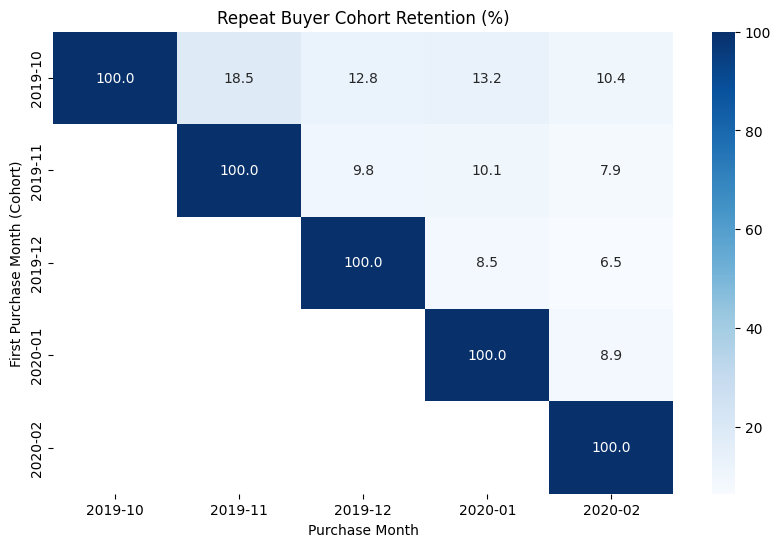

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create cohort retention heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    cohort_retention,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    mask=cohort_retention.isna()
)

plt.title("Repeat Buyer Cohort Retention (%)")
plt.xlabel("Purchase Month")
plt.ylabel("First Purchase Month (Cohort)")
plt.show()

Insight: Repeat purchase retention drops below 20% after the first purchase, so the business should focus on post-purchase engagement strategies such as personalized offers or follow-up campaigns to encourage customers to return.

In [ ]:
# Deliverable 3: Prepare purchase data for revenue analysis

# Keep only completed purchase events
revenue_data = df[df['event_type'] == 'purchase'].copy()

# Calculate total revenue from completed purchases
total_revenue = revenue_data['price'].sum()

print("Total Completed Purchases:", len(revenue_data))
print(f"Total Revenue: ${total_revenue:,.2f}")

# Check missing category information
print("\nMissing Category Codes:")
print(revenue_data['category_code'].isnull().sum())

Total Completed Purchases: 1286102
Total Revenue: $6,344,593.06

Missing Category Codes:
1268946


In [ ]:
# Calculate revenue by product

product_revenue = (
    revenue_data
    .groupby('product_id')
    .agg(
        Total_Revenue=('price', 'sum'),
        Purchase_Count=('price', 'count')
    )
    .sort_values('Total_Revenue', ascending=False)
    .head(10)
    .reset_index()
)

print("Top 10 Products by Revenue:")
print(product_revenue)

Top 10 Products by Revenue:
   product_id  Total_Revenue  Purchase_Count
0     5560754       71726.72             370
1     5809910       39202.47            7549
2     5751422       38229.81            3521
3     5751383       30138.29            2948
4     5850281       29283.62             214
5     5849033       28416.78            2782
6     5792800       27764.36            2711
7     5877454       26832.09             615
8     5560756       24865.44             120
9       89343       24149.61              81


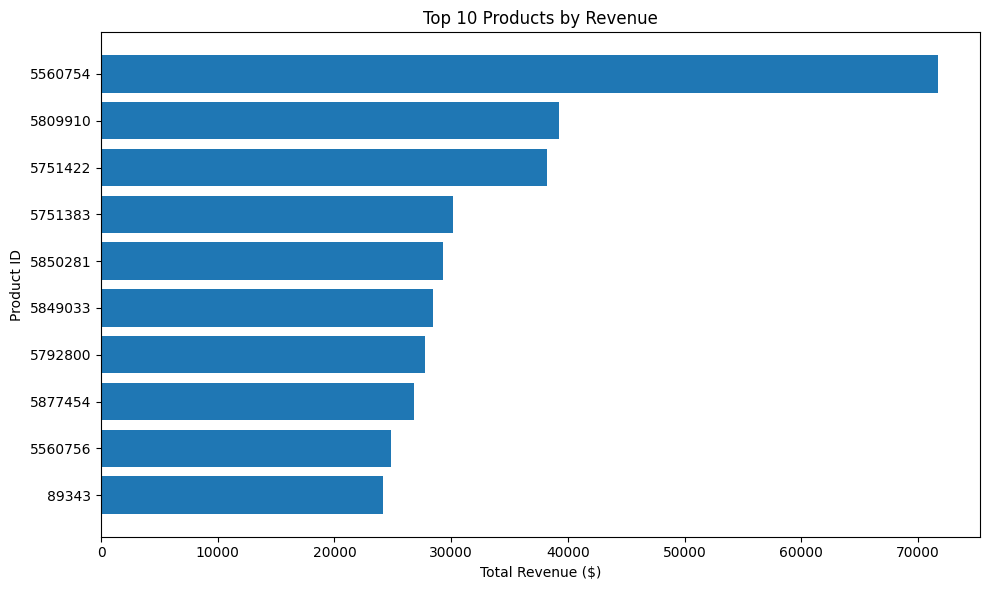

In [ ]:
import matplotlib.pyplot as plt

# Sort data for a horizontal bar chart
chart_product_revenue = product_revenue.sort_values(
    'Total_Revenue',
    ascending=True
)

# Create the chart
plt.figure(figsize=(10, 6))

plt.barh(
    chart_product_revenue['product_id'].astype(str),
    chart_product_revenue['Total_Revenue']
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue ($)')
plt.ylabel('Product ID')

plt.tight_layout()
plt.show()

Insight: Product 5560754 generates the highest revenue despite having relatively few purchases, so the business should identify the characteristics of high-value products and use them to improve revenue from other products.

In [ ]:
# Calculate revenue by category

category_revenue = (
    revenue_data
    .groupby('category_id')
    .agg(
        Total_Revenue=('price', 'sum'),
        Purchase_Count=('price', 'count')
    )
    .sort_values('Total_Revenue', ascending=False)
    .head(10)
    .reset_index()
)

print("Top 10 Categories by Revenue:")
print(category_revenue)

Top 10 Categories by Revenue:
           category_id  Total_Revenue  Purchase_Count
0  1487580005092295511      418307.97           44864
1  1487580006300255120      351672.31            3810
2  1487580005268456287      265282.40           30446
3  1602943681873052386      186388.51           36216
4  1487580006317032337      179951.83           50552
5  1487580008246412266      139889.73           16568
6  1487580006350586771      138623.97            4000
7  1487580013950664926      135889.39            5896
8  1487580005595612013      133904.69           44286
9  1487580009051717646      114642.44            3136


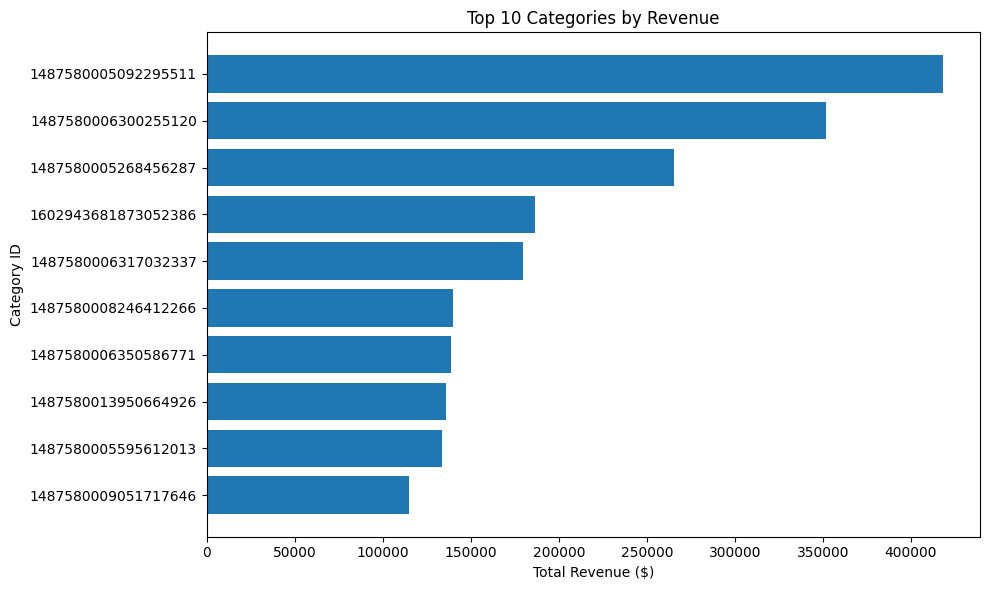

In [ ]:
# Sort data for the horizontal bar chart
chart_category_revenue = category_revenue.sort_values(
    'Total_Revenue',
    ascending=True
)

# Create the chart
plt.figure(figsize=(10, 6))

plt.barh(
    chart_category_revenue['category_id'].astype(str),
    chart_category_revenue['Total_Revenue']
)

plt.title('Top 10 Categories by Revenue')
plt.xlabel('Total Revenue ($)')
plt.ylabel('Category ID')

plt.tight_layout()
plt.show()

Insight: Category 1487580005092295511 generates the highest revenue, so the business should prioritize this category in inventory planning and marketing while analyzing its successful products for opportunities to improve other categories.

In [ ]:
# Deliverable 4: Prepare data for user behaviour heatmap

# Extract the hour from each event
df['hour'] = df['event_time'].dt.hour

# Count events by hour and event type
behaviour_data = (
    df.groupby(['hour', 'event_type'])
    .size()
    .reset_index(name='event_count')
)

# Create a table for the heatmap
behaviour_heatmap = behaviour_data.pivot(
    index='hour',
    columns='event_type',
    values='event_count'
).fillna(0)

# Display the first few rows
print("User Behaviour Pattern Data:")
print(behaviour_heatmap.head())

User Behaviour Pattern Data:
event_type    cart  purchase  remove_from_cart    view
hour                                                  
0            61620     11848             28425   89786
1            56975     11937             27313   76927
2            63111     12295             29548   84933
3            82305     15492             44076  122085
4           112678     22008             58029  181709


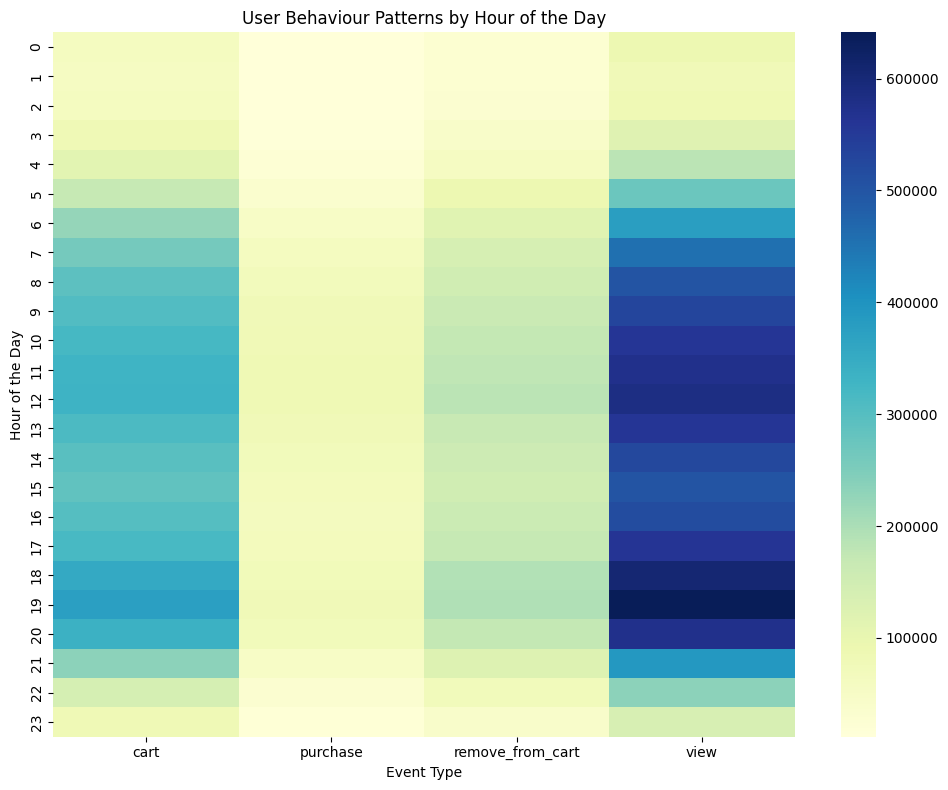

In [ ]:
# Create the User Behaviour Heatmap

plt.figure(figsize=(10, 8))

sns.heatmap(
    behaviour_heatmap,
    cmap='YlGnBu',
    annot=False
)

plt.title('User Behaviour Patterns by Hour of the Day')
plt.xlabel('Event Type')
plt.ylabel('Hour of the Day')

plt.tight_layout()
plt.show()

Insight: User activity, especially product views, is highest during the daytime and evening hours, so the business should schedule promotions and marketing campaigns during these high-activity periods to increase the chances of converting views into purchases.

## **Final Business Recommendation**
The analysis shows that the biggest opportunity is improving the conversion from product views to carts, where 75.07% of users drop off. The business should also strengthen post-purchase engagement to improve repeat buying and use high-performing products, categories, and peak activity periods to support marketing decisions.